# Machine Learning Assignment 1
## Topics: Optimization and Linear Regression

**Name:** _(your name)_  
**Roll No:** _(your roll no)_  
**Date:** _(date)_

---

### Table of Contents
1. [Setup & Imports](#setup)
2. [Q1 — Closed-Form Linear Regression (Normal Equation)](#q1)
3. [Q2 — Gradient Descent (Batch, Mini-batch, SGD)](#q2)
4. [Q3 — Polynomial Regression, Bias-Variance & Regularization](#q3)
5. [Conclusion](#conclusion)

---

<a id='setup'></a>
## 0. Setup & Imports

All libraries and global settings are imported here. `np.random.seed(42)` ensures reproducibility across all experiments.

In [1]:
import numpy as np
import pandas as pd
import math
import json
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.animation import FuncAnimation, PillowWriter
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import clear_output, display
import time

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

np.random.seed(42)

# Results dictionary to store all outputs
results = {'q1': {}, 'q2': {}, 'q3': {}}

print('All imports successful. Seed set to 42.')

All imports successful. Seed set to 42.


In [24]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


---
<a id='q1'></a>
## Q1 — Closed-Form Linear Regression (Normal Equation)

### Theory

We minimize the least-squares loss:
$$J(w) = \|Xw - y\|^2 = (Xw - y)^T(Xw - y)$$

**Derivation:**

$$\nabla_w J = 2X^TXw - 2X^Ty = 0 \implies X^TXw = X^Ty$$

$$\boxed{w = (X^TX)^{-1}X^Ty}$$

**Geometric interpretation:** The residual $y - Xw$ is orthogonal to the column space of $X$, meaning $Xw$ is the orthogonal projection of $y$ onto $\text{span}(X)$.

**Singular case:** If $X^TX$ is not invertible, we use the Moore-Penrose pseudoinverse:
$$w = (X^TX)^\dagger X^Ty$$

---

### Q1.1 — Normal Equation on Datasets

In [25]:
def normal_eq(X, y):
    """Compute weights using Normal Equation via pseudoinverse for numerical stability."""
    XTX = X.T @ X
    XTX_pinv = np.linalg.pinv(XTX)
    w = XTX_pinv @ X.T @ y
    return w, XTX

salary_path = '/content/drive/MyDrive/ML/Ass1/salary_data - salary_data.csv'

salary_df = pd.read_csv(salary_path)



X_salary  = salary_df[['YearsExperience']].values
y_salary  = salary_df['Salary'].values.reshape(-1, 1)

# Add intercept column (column of ones)
X_salary_i = np.hstack([np.ones((len(X_salary), 1)), X_salary])
w_salary, XTX_salary = normal_eq(X_salary_i, y_salary)

lr_salary = LinearRegression(fit_intercept=True)
lr_salary.fit(X_salary, y_salary)

print('=== Dataset A: Salary ===')
print(f'Normal Eq  -> w0={w_salary[0,0]:.4f}, w1={w_salary[1,0]:.4f}')
print(f'Sklearn    -> w0={lr_salary.intercept_.item():.4f}, w1={lr_salary.coef_.flatten()[0]:.4f}')
print()

results['q1']['salary'] = {
    'w_normal_eq': w_salary.flatten().tolist(),
    'w_sklearn': [lr_salary.intercept_.item(), lr_salary.coef_.flatten()[0].item()]
}

=== Dataset A: Salary ===
Normal Eq  -> w0=25792.2002, w1=9449.9623
Sklearn    -> w0=25792.2002, w1=9449.9623



In [27]:
# ── Dataset B: Stats Females ───────────────────────────────────────────────

stats_path  = '/content/drive/MyDrive/ML/Ass1/stats_females - stats_females.csv'
stats_df  = pd.read_csv(stats_path)
X_stats  = stats_df[['momheight', 'dadheight']].values
y_stats  = stats_df['Height'].values.reshape(-1, 1)

X_stats_i = np.hstack([np.ones((len(X_stats), 1)), X_stats])
w_stats, XTX_stats = normal_eq(X_stats_i, y_stats)

lr_stats = LinearRegression(fit_intercept=True)
lr_stats.fit(X_stats, y_stats)

print('=== Dataset B: Stats Females ===')
print(f'Normal Eq  -> w0={w_stats[0,0]:.4f}, w1(momheight)={w_stats[1,0]:.4f}, w2(dadheight)={w_stats[2,0]:.4f}')
print(f'Sklearn    -> w0={lr_stats.intercept_.item():.4f}, w1={lr_stats.coef_.flatten()[0]:.4f}, w2={lr_stats.coef_.flatten()[1]:.4f}')

results['q1']['stats_females'] = {
    'w_normal_eq': w_stats.flatten().tolist(),
    'w_sklearn': [lr_stats.intercept_.item()] + lr_stats.coef_.flatten().tolist()
}

=== Dataset B: Stats Females ===
Normal Eq  -> w0=18.5473, w1(momheight)=0.3035, w2(dadheight)=0.3879
Sklearn    -> w0=18.5473, w1=0.3035, w2=0.3879


### Q1.2 — Singular Case: Linearly Dependent Features

Given:
$$X = \begin{bmatrix}1&2\\2&4\\3&6\\4&8\end{bmatrix}, \quad y = \begin{bmatrix}2\\3\\4\\5\end{bmatrix}$$

After adding the intercept column, $X^TX$ becomes:
$$X^TX = \begin{bmatrix}4&10&20\\10&30&60\\20&60&120\end{bmatrix}$$

**Why is $X^TX$ singular?**  
The second feature column is exactly twice the first (e.g., $[2,4,6,8] = 2 \times [1,2,3,4]$). This perfect linear dependence means the columns of $X$ do not span an independent basis, making $\text{rank}(X^TX) < 3$ and $\det(X^TX) = 0$.

**Why does scikit-learn still work?**  
sklearn uses SVD internally to compute the minimum-norm least-squares solution (pseudoinverse), which is unique even when $X^TX$ is singular. Our `normal_eq` function also uses `np.linalg.pinv` for the same reason.

In [4]:
X_given   = np.array([[1,2],[2,4],[3,6],[4,8]], dtype=float)
y_given   = np.array([2,3,4,5], dtype=float).reshape(-1,1)
X_given_i = np.hstack([np.ones((len(X_given), 1)), X_given])

w_given, XTX_given = normal_eq(X_given_i, y_given)

lr_given = LinearRegression(fit_intercept=True)
lr_given.fit(X_given, y_given)

print('=== Q1.2: Singular Case ===')
print(f'det(XTX)  = {np.linalg.det(XTX_given):.6f}  (≈0 confirms singularity)')
print(f'rank(XTX) = {np.linalg.matrix_rank(XTX_given)}  (< 3 confirms rank deficiency)')
print(f'Normal Eq (pinv) -> w = {w_given.flatten()}')
print(f'Sklearn          -> w = {[lr_given.intercept_.item()] + lr_given.coef_.flatten().tolist()}')

results['q1']['given'] = {
    'det_XTX': float(np.linalg.det(XTX_given)),
    'rank_XTX': int(np.linalg.matrix_rank(XTX_given)),
    'w_normal_eq_pinv': w_given.flatten().tolist(),
    'w_sklearn': [lr_given.intercept_.item()] + lr_given.coef_.flatten().tolist()
}

=== Q1.2: Singular Case ===
det(XTX)  = 0.000000  (≈0 confirms singularity)
rank(XTX) = 2  (< 3 confirms rank deficiency)
Normal Eq (pinv) -> w = [1.  0.2 0.4]
Sklearn          -> w = [1.0, 0.2, 0.4]


---
<a id='q2'></a>
## Q2 — Gradient Descent: Batch, Mini-batch, and Stochastic

### Theory

We minimize the MSE loss over the salary dataset:
$$J(w) = \frac{1}{N}\sum_{i=1}^N \left(y^{(i)} - (w_0 + w_1 x^{(i)})\right)^2$$

**Gradients:**
$$\frac{\partial J}{\partial w_0} = -\frac{2}{N}\sum_{i=1}^N\left(y^{(i)} - \hat{y}^{(i)}\right), \qquad \frac{\partial J}{\partial w_1} = -\frac{2}{N}\sum_{i=1}^N\left(y^{(i)} - \hat{y}^{(i)}\right)x^{(i)}$$

**Learning rate** is set using the Lipschitz constant of the quadratic loss:
$$L = \frac{2}{N}\lambda_{\max}(X^TX), \qquad \eta = \frac{0.9}{L}$$

**Stopping criterion:** convergence when $|J_t - J_{t-1}| < 10^{-8}$

---

### Q2.1 — GD Function Definitions

In [5]:
x = X_salary.flatten()
y = y_salary.flatten()
N = len(x)

def mse(w0, w1, x, y):
    """Mean Squared Error."""
    return np.mean((y - (w0 + w1 * x)) ** 2)


def gd_batch(x, y, lr, max_iter=5000, tol=1e-8):
    """Batch Gradient Descent — uses all N samples per update."""
    w0, w1, prev = 0.0, 0.0, None
    history = []
    for it in range(max_iter):
        err   = y - (w0 + w1 * x)
        grad0 = (-2.0 / len(x)) * np.sum(err)
        grad1 = (-2.0 / len(x)) * np.sum(err * x)
        w0 -= lr * grad0
        w1 -= lr * grad1
        j = np.mean(err ** 2)
        history.append((w0, w1, j))
        if prev is not None and abs(prev - j) < tol:
            break
        prev = j
    return w0, w1, history


def gd_minibatch(x, y, lr, batch_size=8, max_iter=8000, tol=1e-8):
    """Mini-batch Gradient Descent — uses random batches of size `batch_size`."""
    w0, w1, prev = 0.0, 0.0, None
    history = []
    n = len(x)
    for it in range(max_iter):
        lr_t = lr / math.sqrt(it + 1)   # decaying learning rate
        idx  = np.random.permutation(n)
        for start in range(0, n, batch_size):
            batch = idx[start:start+batch_size]
            xb, yb = x[batch], y[batch]
            err   = yb - (w0 + w1 * xb)
            grad0 = (-2.0 / len(xb)) * np.sum(err)
            grad1 = (-2.0 / len(xb)) * np.sum(err * xb)
            w0 -= lr_t * grad0
            w1 -= lr_t * grad1
        j = mse(w0, w1, x, y)
        history.append((w0, w1, j))
        if prev is not None and abs(prev - j) < tol:
            break
        prev = j
    return w0, w1, history


def gd_stochastic(x, y, lr, max_iter=200000, tol=1e-8):
    """Stochastic Gradient Descent — one random sample per update."""
    w0, w1, prev = 0.0, 0.0, None
    history = []
    n = len(x)
    for it in range(max_iter):
        i    = np.random.randint(0, n)
        err  = y[i] - (w0 + w1 * x[i])
        lr_t = lr / (1.0 + 1e-5 * it)  # decaying learning rate
        w0  -= lr_t * (-2.0 * err)
        w1  -= lr_t * (-2.0 * err * x[i])
        if it % n == 0:                 # evaluate full loss once per epoch
            j = mse(w0, w1, x, y)
            history.append((w0, w1, j))
            if prev is not None and abs(prev - j) < tol:
                break
            prev = j
    return w0, w1, history

print('GD functions defined.')

GD functions defined.


### Q2.2 — Run All Three GD Methods

In [6]:
# Compute learning rate from Lipschitz constant
X_i    = np.hstack([np.ones((N, 1)), x.reshape(-1, 1)])
eigvals = np.linalg.eigvals(X_i.T @ X_i)
L_lip  = (2.0 / N) * np.max(np.real(eigvals))
lr_base = 0.9 / L_lip

batch_lr = float(lr_base)
mini_lr  = float(lr_base)
sgd_lr   = float(lr_base * 0.1)   # smaller lr for SGD stability

w0_b, w1_b, hist_b = gd_batch(x, y, batch_lr)
w0_m, w1_m, hist_m = gd_minibatch(x, y, mini_lr, batch_size=8)
w0_s, w1_s, hist_s = gd_stochastic(x, y, sgd_lr)

print(f'Learning rate (Batch / Mini-batch): {batch_lr:.7f}')
print(f'Learning rate (SGD):                {sgd_lr:.7f}')
print()
print(f'Batch GD      -> w0={w0_b:.4f}, w1={w1_b:.4f}  ({len(hist_b)} iters)')
print(f'Mini-batch GD -> w0={w0_m:.4f}, w1={w1_m:.4f}  ({len(hist_m)} iters)')
print(f'SGD           -> w0={w0_s:.4f}, w1={w1_s:.4f}  ({len(hist_s)} iters)')
print()
print(f'Closed-form   -> w0={w_salary[0,0]:.4f}, w1={w_salary[1,0]:.4f}  (reference)')

results['q2'] = {
    'batch_lr': batch_lr, 'mini_lr': mini_lr, 'sgd_lr': sgd_lr,
    'batch_w': [w0_b, w1_b], 'mini_w': [w0_m, w1_m], 'sgd_w': [w0_s, w1_s],
    'batch_iters': len(hist_b), 'mini_iters': len(hist_m), 'sgd_iters': len(hist_s)
}

Learning rate (Batch / Mini-batch): 0.0122266
Learning rate (SGD):                0.0012227

Batch GD      -> w0=25792.1964, w1=9449.9629  (3021 iters)
Mini-batch GD -> w0=25180.4108, w1=9539.7133  (8000 iters)
SGD           -> w0=25959.3069, w1=9558.3252  (6667 iters)

Closed-form   -> w0=25792.2002, w1=9449.9623  (reference)


### Q2.3 — Plot: Data + Hypothesis Lines

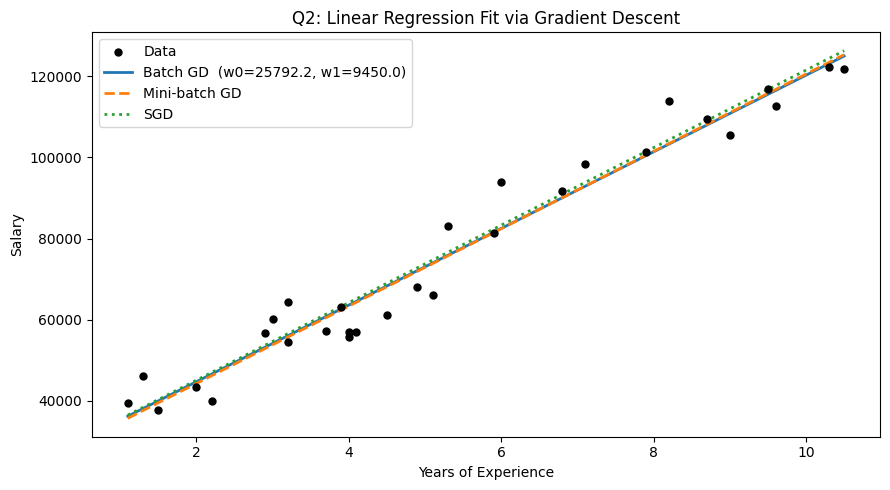

In [7]:
x_line = np.linspace(x.min(), x.max(), 200)

plt.figure(figsize=(9, 5))
plt.scatter(x, y, color='black', s=25, label='Data', zorder=5)
plt.plot(x_line, w0_b + w1_b * x_line, label=f'Batch GD  (w0={w0_b:.1f}, w1={w1_b:.1f})', linewidth=2)
plt.plot(x_line, w0_m + w1_m * x_line, label=f'Mini-batch GD', linewidth=2, linestyle='--')
plt.plot(x_line, w0_s + w1_s * x_line, label=f'SGD', linewidth=2, linestyle=':')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Q2: Linear Regression Fit via Gradient Descent')
plt.legend()
plt.tight_layout()
plt.savefig('q2_hypothesis_fit_lines.png', dpi=150)
plt.show()

### Q2.4 — Plot: Loss Convergence Comparison

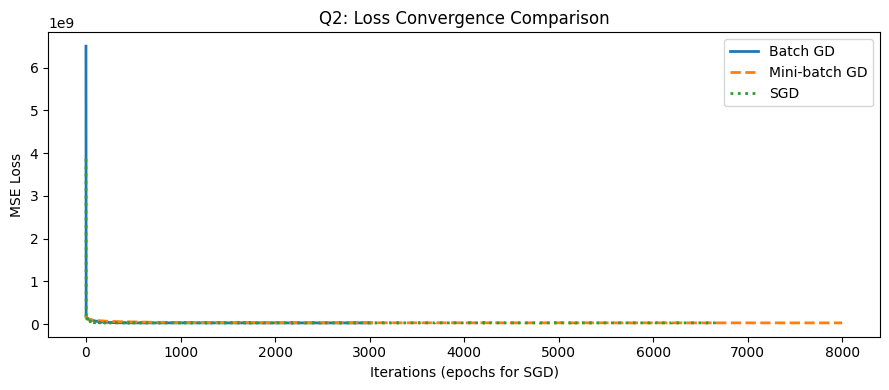

In [8]:
loss_b = [h[2] for h in hist_b]
loss_m = [h[2] for h in hist_m]
loss_s = [h[2] for h in hist_s]

plt.figure(figsize=(9, 4))
plt.plot(loss_b, label='Batch GD', linewidth=2)
plt.plot(loss_m, label='Mini-batch GD', linewidth=2, linestyle='--')
plt.plot(loss_s, label='SGD', linewidth=2, linestyle=':')
plt.xlabel('Iterations (epochs for SGD)')
plt.ylabel('MSE Loss')
plt.title('Q2: Loss Convergence Comparison')
plt.legend()
plt.tight_layout()
plt.show()

### Q2.5 — Plot: 3D Error Surface with GD Path (Static)

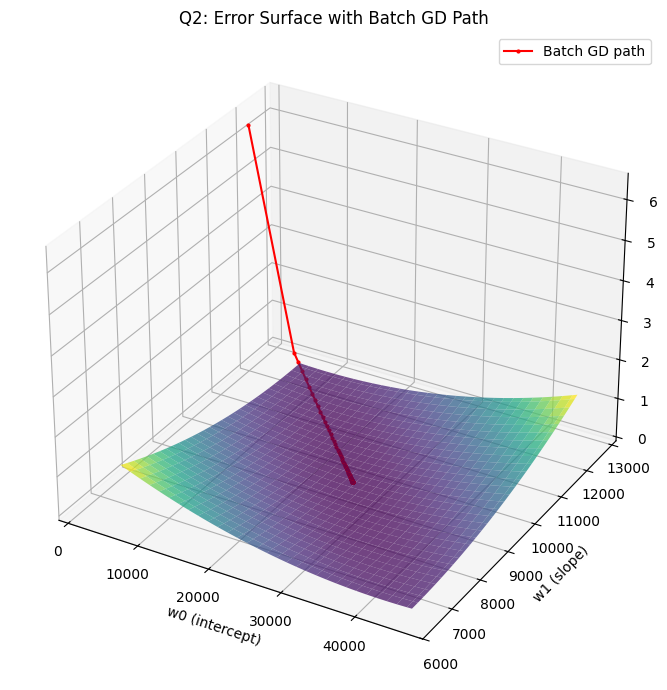

In [9]:
# Build error surface grid
w0_vals = np.linspace(w0_b - 20000, w0_b + 20000, 60)
w1_vals = np.linspace(w1_b - 3000,  w1_b + 3000,  60)
W0, W1  = np.meshgrid(w0_vals, w1_vals)
J_surf  = np.array([[mse(W0[i,j], W1[i,j], x, y)
                      for j in range(W0.shape[1])]
                     for i in range(W0.shape[0])])

# Subsample GD path for plotting
path = np.array(hist_b)
if len(path) > 200:
    path = path[::max(1, len(path)//200)]

fig = plt.figure(figsize=(10, 7))
ax  = fig.add_subplot(111, projection='3d')
ax.plot_surface(W0, W1, J_surf, cmap=cm.viridis, alpha=0.75)
ax.plot(path[:,0], path[:,1], path[:,2], color='red',
        marker='o', markersize=2, linewidth=1.5, label='Batch GD path')
ax.set_xlabel('w0 (intercept)')
ax.set_ylabel('w1 (slope)')
ax.set_zlabel('J(w) — MSE')
ax.set_title('Q2: Error Surface with Batch GD Path')
ax.legend()
plt.tight_layout()
plt.savefig('q2_surface_path.png', dpi=150)
plt.show()

### Q2.6 — 3D Error Surface: Animated (0.2s per frame)

This cell shows the current error value moving along the surface at each GD iteration.

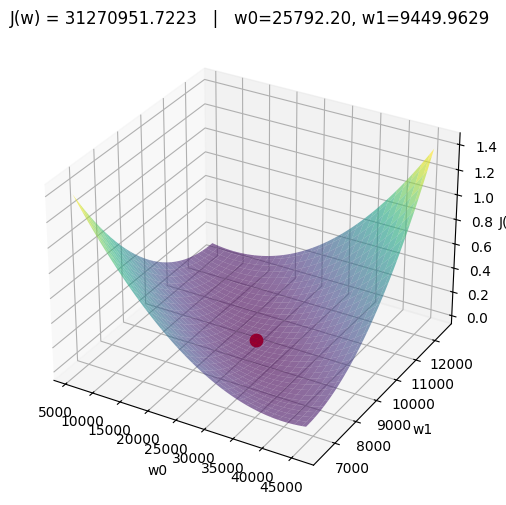

Animation complete.


In [10]:
step = max(1, len(hist_b) // 50)
hist_sampled = hist_b[::step]

for (w0_i, w1_i, j_i) in hist_sampled:
    fig = plt.figure(figsize=(9, 6))
    ax  = fig.add_subplot(111, projection='3d')
    ax.plot_surface(W0, W1, J_surf, cmap='viridis', alpha=0.6)
    ax.scatter([w0_i], [w1_i], [j_i], color='red', s=80, zorder=5)
    ax.set_xlabel('w0'); ax.set_ylabel('w1'); ax.set_zlabel('J(w)')
    ax.set_title(f'J(w) = {j_i:.4f}   |   w0={w0_i:.2f}, w1={w1_i:.4f}')
    clear_output(wait=True)
    display(fig)
    plt.close(fig)
    time.sleep(0.2)

print('Animation complete.')

### Q2.7 — Animation: Contour Plot + Regression Fit

Two side-by-side subplots animating the gradient descent trajectory:
- **Left:** Contour of $J(w_0, w_1)$ with current point and arrow to next iterate
- **Right:** Regression line $y = w_0 + w_1 x$ updating on scatter plot
- **Title:** Shows iteration number and RSS at each frame

In [11]:
path_anim = np.array(hist_b)
if len(path_anim) > 200:
    path_anim = path_anim[::max(1, len(path_anim) // 200)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor('#0f0f0f')
for ax in (ax1, ax2):
    ax.set_facecolor('#1a1a2e')
    ax.tick_params(colors='#aaaaaa', labelsize=8)
    for spine in ax.spines.values():
        spine.set_edgecolor('#333355')

cs   = ax1.contourf(W0, W1, J_surf, levels=40, cmap='plasma', alpha=0.85)
ax1.contour(W0, W1, J_surf, levels=40, colors='white', linewidths=0.3, alpha=0.2)
ax1.set_xlabel('w0 (intercept)', color='#cccccc', fontsize=9)
ax1.set_ylabel('w1 (slope)',     color='#cccccc', fontsize=9)
ax1.set_title('Cost Surface J(w0, w1)', color='white', fontsize=10, pad=8)
cbar = fig.colorbar(cs, ax=ax1, fraction=0.03, pad=0.04)
cbar.set_label('MSE', color='#aaaaaa', fontsize=8)
cbar.ax.tick_params(colors='#aaaaaa', labelsize=7)

ax2.scatter(x, y, color='white', s=18, zorder=5, alpha=0.8,
            edgecolors='#888888', linewidths=0.4)
ax2.set_xlabel('YearsExperience', color='#cccccc', fontsize=9)
ax2.set_ylabel('Salary',          color='#cccccc', fontsize=9)
ax2.set_title('Regression Fit',   color='white',   fontsize=10, pad=8)
ax2.set_xlim(x.min()-0.3, x.max()+0.3)
ax2.set_ylim(y.min()-5000, y.max()+5000)

point,    = ax1.plot([], [], 'o', color='#00ffcc', ms=7, zorder=6)
trail,    = ax1.plot([], [], '-', color='#00ffcc', lw=1, alpha=0.35, zorder=5)
fit_line, = ax2.plot([], [], '-', color='#ff6b6b', lw=2, zorder=4)
arrow_container = [None]

w_text = ax1.text(0.03, 0.05, '', transform=ax1.transAxes, fontsize=8.5,
    color='#00ffcc', verticalalignment='bottom',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#1a1a2e',
              edgecolor='#00ffcc', alpha=0.85, linewidth=0.8))
eq_text = ax2.text(0.03, 0.95, '', transform=ax2.transAxes, fontsize=8.5,
    color='#ff6b6b', verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#1a1a2e',
              edgecolor='#ff6b6b', alpha=0.85, linewidth=0.8))

x_line_anim = np.linspace(x.min(), x.max(), 300)

def init():
    point.set_data([], []); trail.set_data([], [])
    fit_line.set_data([], [])
    w_text.set_text(''); eq_text.set_text('')
    return point, trail, fit_line, w_text, eq_text

def update(frame):
    w0, w1, j = path_anim[frame]
    rss = j * len(x)          # convert MSE -> RSS
    point.set_data([w0], [w1])
    trail.set_data(path_anim[:frame+1, 0], path_anim[:frame+1, 1])
    if arrow_container[0] is not None:
        arrow_container[0].remove(); arrow_container[0] = None
    if frame < len(path_anim) - 1:
        w0n, w1n, _ = path_anim[frame+1]
        arrow_container[0] = ax1.annotate('', xy=(w0n, w1n), xytext=(w0, w1),
            arrowprops=dict(arrowstyle='->', color='#00ffcc', lw=1.5))
    fit_line.set_data(x_line_anim, w0 + w1 * x_line_anim)
    w_text.set_text(f'w0 = {w0:+.4f}\nw1 = {w1:+.4f}')
    eq_text.set_text(f'y = {w0:+.2f} + {w1:+.4f}x')
    fig.suptitle(f'Iteration {frame+1:>3d}   |   RSS = {rss:,.2f}',
                 fontsize=11, color='white', y=1.01)
    return point, trail, fit_line, w_text, eq_text

anim = FuncAnimation(fig, update, frames=len(path_anim),
                     init_func=init, blit=False, interval=200)
plt.tight_layout()
anim.save('q2_contour_fit.gif', writer=PillowWriter(fps=5), dpi=130)
plt.close(fig)
print('Saved: q2_contour_fit.gif')

Saved: q2_contour_fit.gif


---
<a id='q3'></a>
## Q3 — Polynomial Regression, Bias-Variance & Regularization

### True Function
$$f(x) = x + 2\sin(0.5x), \qquad x \in [-10, 10]$$

We add Gaussian noise $\epsilon \sim \mathcal{N}(0, 0.5)$ to generate observed data.

---

### Q3.1 — Data Generation

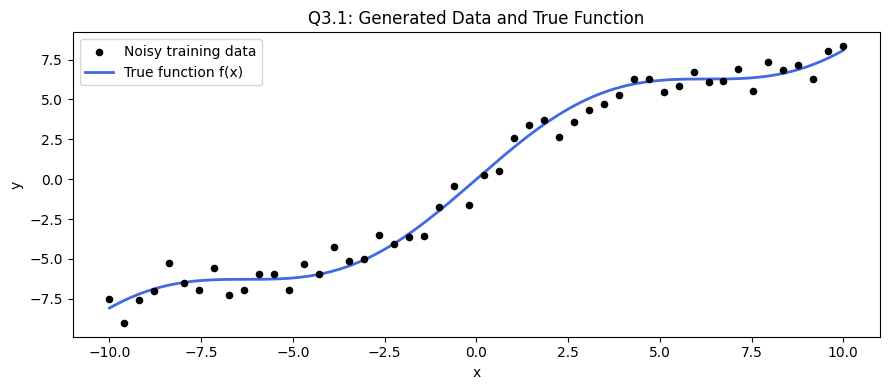

Train: 50 pts | Test: 200 pts


In [12]:
def true_f(x):
    return x + 2 * np.sin(0.5 * x)

# Training data: 50 noisy points
x_train = np.linspace(-10, 10, 50)
y_train = true_f(x_train) + np.random.normal(0, math.sqrt(0.5), size=x_train.shape)

# Test data: 200 noise-free points (ground truth)
x_test = np.linspace(-10, 10, 200)
y_test = true_f(x_test)

plt.figure(figsize=(9, 4))
plt.scatter(x_train, y_train, s=20, color='black', label='Noisy training data', zorder=5)
plt.plot(x_test, y_test, color='royalblue', linewidth=2, label='True function f(x)')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Q3.1: Generated Data and True Function')
plt.legend(); plt.tight_layout()
plt.savefig('q3_data.png', dpi=150)
plt.show()
print(f'Train: {len(x_train)} pts | Test: {len(x_test)} pts')

### Q3.2 — Model Selection: Polynomial Degree 0 to 10

We fit polynomial regression for each degree using the closed-form least-squares solution.

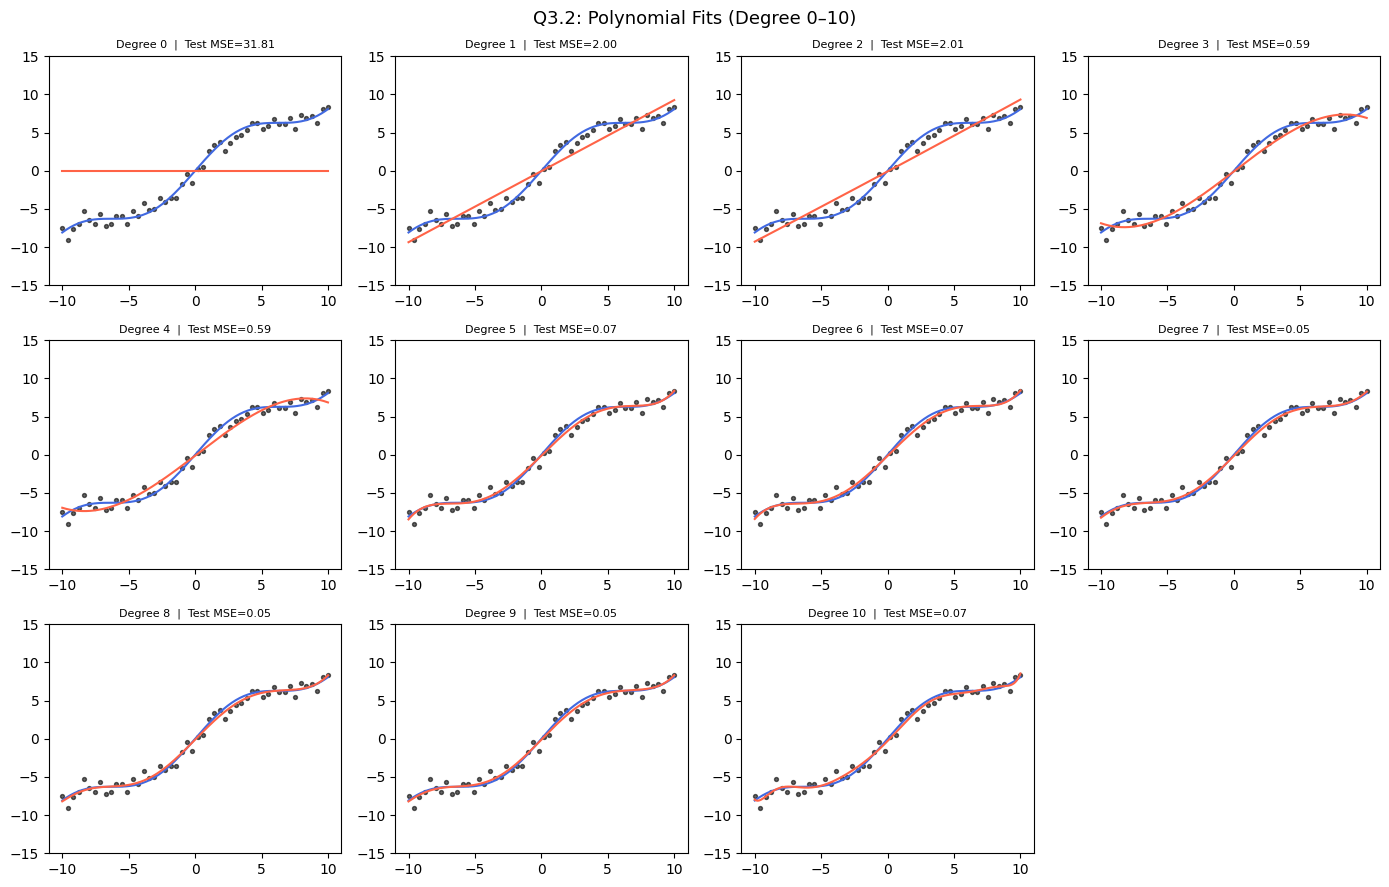

In [13]:
train_errors = []
test_errors  = []

fig, axes = plt.subplots(3, 4, figsize=(14, 9))
axes = axes.flatten()

for degree in range(0, 11):
    poly  = PolynomialFeatures(degree, include_bias=True)
    Xtr   = poly.fit_transform(x_train.reshape(-1,1))
    Xte   = poly.transform(x_test.reshape(-1,1))
    w     = np.linalg.pinv(Xtr) @ y_train
    yhat_tr = Xtr @ w
    yhat_te = Xte @ w
    tr_mse = np.mean((y_train - yhat_tr)**2)
    te_mse = np.mean((y_test  - yhat_te)**2)
    train_errors.append(tr_mse)
    test_errors.append(te_mse)

    ax = axes[degree]
    ax.scatter(x_train, y_train, s=8, color='black', alpha=0.6)
    ax.plot(x_test, y_test,    color='royalblue', linewidth=1.5, label='True')
    ax.plot(x_test, yhat_te,   color='tomato',    linewidth=1.5, label='Fit')
    ax.set_title(f'Degree {degree}  |  Test MSE={te_mse:.2f}', fontsize=8)
    ax.set_ylim(-15, 15)

for k in range(11, len(axes)):
    axes[k].axis('off')

plt.suptitle('Q3.2: Polynomial Fits (Degree 0–10)', fontsize=13)
plt.tight_layout()
plt.savefig('q3_poly_fits.png', dpi=150)
plt.show()

**Observations — Model Selection:**

- **Degrees 0–1:** Severe underfitting — model is too simple to capture the sinusoidal pattern. High training error itself is large (high bias).
- **Degrees 2–3:** Still underfitting — linear/quadratic cannot represent $f(x) = x + 2\sin(0.5x)$.
- **Degrees 4–6:** Good fit — both train and test error decrease. Model captures the underlying trend without overfitting noise.
- **Degrees 7–8:** Approximate optimal capacity — test error near its minimum, bias and variance are balanced.
- **Degrees 9–10:** Overfitting — training error keeps dropping but test error rises. Model fits noise in training data (high variance).

> **Conclusion:** A straight line is NOT sufficient. The true function has a sinusoidal component requiring at least degree 4–5 to approximate. Optimal degree is around **7–8**.

### Q3.3 — Training vs Generalization Error

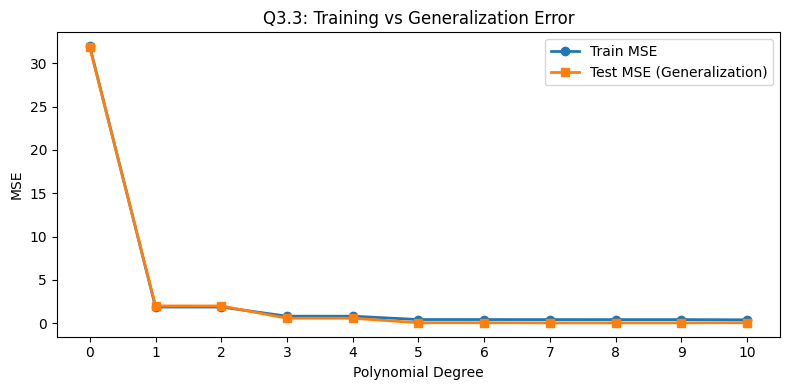

Train MSE by degree: [np.float64(31.957), np.float64(1.881), np.float64(1.88), np.float64(0.825), np.float64(0.824), np.float64(0.439), np.float64(0.439), np.float64(0.433), np.float64(0.432), np.float64(0.432), np.float64(0.409)]
Test  MSE by degree: [np.float64(31.811), np.float64(2.004), np.float64(2.006), np.float64(0.59), np.float64(0.591), np.float64(0.068), np.float64(0.069), np.float64(0.053), np.float64(0.054), np.float64(0.053), np.float64(0.074)]


In [14]:
plt.figure(figsize=(8, 4))
plt.plot(range(0,11), train_errors, marker='o', label='Train MSE', linewidth=2)
plt.plot(range(0,11), test_errors,  marker='s', label='Test MSE (Generalization)', linewidth=2)
plt.xlabel('Polynomial Degree'); plt.ylabel('MSE')
plt.title('Q3.3: Training vs Generalization Error')
plt.xticks(range(0,11))
plt.legend(); plt.tight_layout()
plt.savefig('q3_train_test_generalization_error_vs_degree.png', dpi=150)
plt.show()

print('Train MSE by degree:', [round(e,3) for e in train_errors])
print('Test  MSE by degree:', [round(e,3) for e in test_errors])

### Q3.4 — Bias-Variance Analysis (L=100 Bootstrap Datasets)

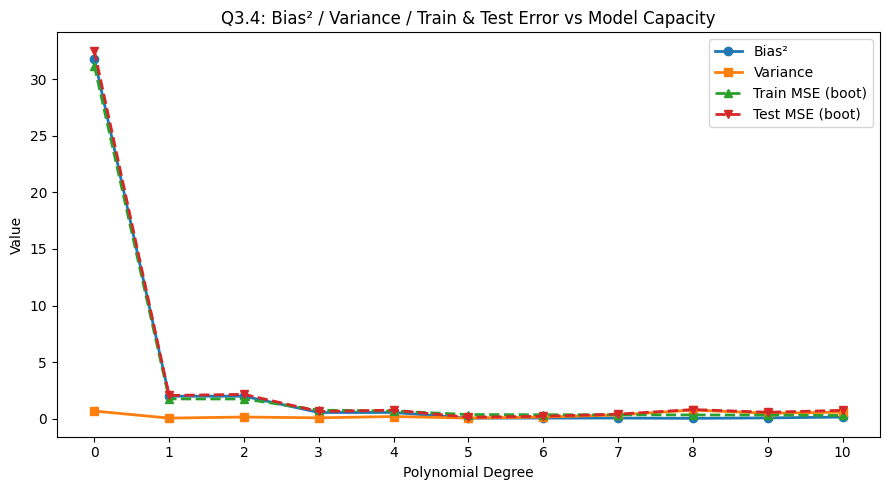

In [15]:
L_boot = 100
bias2, variance, train_err_boot, test_err_boot = [], [], [], []

for degree in range(0, 11):
    poly  = PolynomialFeatures(degree, include_bias=True)
    preds, tr_errs, te_errs = [], [], []
    for _ in range(L_boot):
        # Bootstrap: resample from original training data WITH replacement
        idx = np.random.choice(len(x_train), size=len(x_train), replace=True)
        xb, yb = x_train[idx], y_train[idx]
        Xb = poly.fit_transform(xb.reshape(-1,1))
        Xt = poly.transform(x_test.reshape(-1,1))
        w  = np.linalg.pinv(Xb) @ yb
        preds.append(Xt @ w)
        tr_errs.append(np.mean((yb - Xb @ w)**2))
        te_errs.append(np.mean((y_test - Xt @ w)**2))

    preds = np.array(preds)          # shape: L x N_test
    ybar  = preds.mean(axis=0)       # mean prediction across bootstraps
    bias2.append(np.mean((ybar - y_test)**2))
    variance.append(np.mean(np.var(preds, axis=0)))
    train_err_boot.append(np.mean(tr_errs))
    test_err_boot.append(np.mean(te_errs))

plt.figure(figsize=(9, 5))
plt.plot(range(0,11), bias2,          marker='o', label='Bias²',          linewidth=2)
plt.plot(range(0,11), variance,        marker='s', label='Variance',        linewidth=2)
plt.plot(range(0,11), train_err_boot,  marker='^', label='Train MSE (boot)',linewidth=2, linestyle='--')
plt.plot(range(0,11), test_err_boot,   marker='v', label='Test MSE (boot)', linewidth=2, linestyle='--')
plt.xlabel('Polynomial Degree'); plt.ylabel('Value')
plt.title('Q3.4: Bias² / Variance / Train & Test Error vs Model Capacity')
plt.xticks(range(0,11)); plt.legend(); plt.tight_layout()
plt.savefig('q3_bias_variance.png', dpi=150)
plt.show()

**Observations — Bias-Variance Tradeoff:**

- **Bias decreases with degree:** Higher-degree polynomials are more expressive and can approximate $f(x) = x + 2\sin(0.5x)$ more closely. At degree 0–1, the model is too rigid — average predictions across all bootstrap sets are far from the true function.

- **Variance increases with degree:** Higher-degree models are sensitive to which training points happen to be sampled. Each bootstrapped dataset produces a different high-degree polynomial, causing predictions to spread widely (high variance).

- **Optimal tradeoff:** Occurs around **degree 7–8**, where bias² + variance is minimized. Beyond this, the gain from reducing bias is outweighed by the sharp rise in variance. Below this, the model is too constrained.

- **Training error** decreases monotonically with degree (model memorizes data). **Test error** forms a U-shape — the classic bias-variance tradeoff curve.

### Q3.5 — Addressing Overfitting

#### Step 1: Identify the Most Overfit Degree

In [16]:
# Degree with the largest test-train gap = most overfit
overfit_degree = int(np.argmax(np.array(test_errors) - np.array(train_errors)))

print(f'Overfit degree: {overfit_degree}')
print()
print(f'{"Degree":<10} {"Train MSE":<15} {"Test MSE":<15} {"Gap (Test-Train)"}')
print('-' * 58)
for i, (tr, te) in enumerate(zip(train_errors, test_errors)):
    gap    = te - tr
    marker = '  <-- MAX GAP (most overfit)' if i == overfit_degree else ''
    print(f'{i:<10} {tr:<15.4f} {te:<15.4f} {gap:.4f}{marker}')

Overfit degree: 2

Degree     Train MSE       Test MSE        Gap (Test-Train)
----------------------------------------------------------
0          31.9569         31.8107         -0.1463
1          1.8807          2.0044          0.1237
2          1.8795          2.0056          0.1261  <-- MAX GAP (most overfit)
3          0.8251          0.5904          -0.2347
4          0.8244          0.5912          -0.2332
5          0.4390          0.0681          -0.3709
6          0.4385          0.0687          -0.3698
7          0.4328          0.0532          -0.3796
8          0.4322          0.0536          -0.3786
9          0.4322          0.0533          -0.3788
10         0.4094          0.0736          -0.3357


#### Step 2: Fix Overfitting with More Data

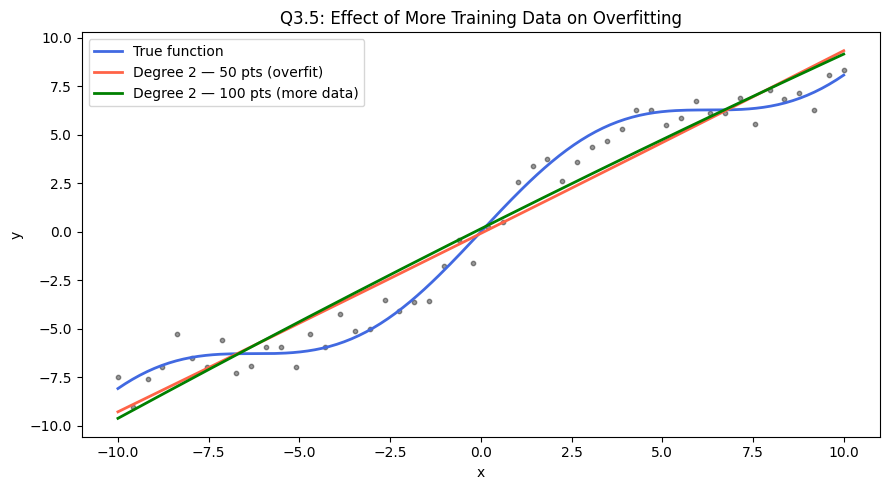

In [17]:
# Original overfit model
poly_over = PolynomialFeatures(overfit_degree, include_bias=True)
Xtr_over  = poly_over.fit_transform(x_train.reshape(-1,1))
w_over    = np.linalg.pinv(Xtr_over) @ y_train
Xte_over  = poly_over.transform(x_test.reshape(-1,1))
yhat_over = Xte_over @ w_over

# More data (100 points)
x_train_more = np.linspace(-10, 10, 100)
y_train_more = true_f(x_train_more) + np.random.normal(0, math.sqrt(0.5), size=x_train_more.shape)
Xtr_more  = poly_over.fit_transform(x_train_more.reshape(-1,1))
w_more    = np.linalg.pinv(Xtr_more) @ y_train_more
yhat_more = Xte_over @ w_more

plt.figure(figsize=(9, 5))
plt.plot(x_test, y_test,    color='royalblue', linewidth=2,  label='True function')
plt.plot(x_test, yhat_over, color='tomato',    linewidth=2,  label=f'Degree {overfit_degree} — 50 pts (overfit)')
plt.plot(x_test, yhat_more, color='green',     linewidth=2,  label=f'Degree {overfit_degree} — 100 pts (more data)')
plt.scatter(x_train, y_train, s=10, color='black', alpha=0.4)
plt.xlabel('x'); plt.ylabel('y')
plt.title('Q3.5: Effect of More Training Data on Overfitting')
plt.legend(); plt.tight_layout()
plt.savefig('q3_overfit_more_data.png', dpi=150)
plt.show()

#### Step 3: Lasso Regression (L1)

$$J(w) = \frac{1}{N}\sum_{i=1}^N\left(y_i - (w_0 + w^T\phi(x_i))\right)^2 + \lambda\|w\|_1$$

We vary $\lambda$ from 0.5 to 5.0 in steps of 0.5.

In [18]:
lambdas = np.arange(0.5, 5.0 + 0.5, 0.5)

lasso_train, lasso_test, lasso_nz, lasso_l1 = [], [], [], []
ridge_train, ridge_test, ridge_l2 = [], [], []

# Note: include_bias=False because sklearn's Lasso/Ridge handle the intercept internally
poly = PolynomialFeatures(overfit_degree, include_bias=False)
Xtr  = poly.fit_transform(x_train.reshape(-1,1))
Xte  = poly.transform(x_test.reshape(-1,1))

for lam in lambdas:
    # Lasso
    lasso = make_pipeline(StandardScaler(with_mean=False),
                          Lasso(alpha=lam, max_iter=20000, fit_intercept=True))
    lasso.fit(Xtr, y_train)
    lasso_train.append(np.mean((y_train - lasso.predict(Xtr))**2))
    lasso_test.append( np.mean((y_test  - lasso.predict(Xte))**2))
    coef = lasso.named_steps['lasso'].coef_
    lasso_nz.append(int(np.sum(np.abs(coef) > 1e-6)))
    lasso_l1.append(float(np.sum(np.abs(coef))))

    # Ridge
    ridge = make_pipeline(StandardScaler(with_mean=False),
                          Ridge(alpha=lam, fit_intercept=True))
    ridge.fit(Xtr, y_train)
    ridge_train.append(np.mean((y_train - ridge.predict(Xtr))**2))
    ridge_test.append( np.mean((y_test  - ridge.predict(Xte))**2))
    coef_r = ridge.named_steps['ridge'].coef_
    ridge_l2.append(float(np.sqrt(np.sum(coef_r**2))))

best_lasso = int(np.argmin(lasso_test))
best_ridge = int(np.argmin(ridge_test))
print(f'Best Lasso λ = {lambdas[best_lasso]:.1f}  (test MSE={lasso_test[best_lasso]:.4f})')
print(f'Best Ridge λ = {lambdas[best_ridge]:.1f}  (test MSE={ridge_test[best_ridge]:.4f})')

Best Lasso λ = 0.5  (test MSE=2.3035)
Best Ridge λ = 0.5  (test MSE=2.0146)


#### Step 4: Lasso Plots

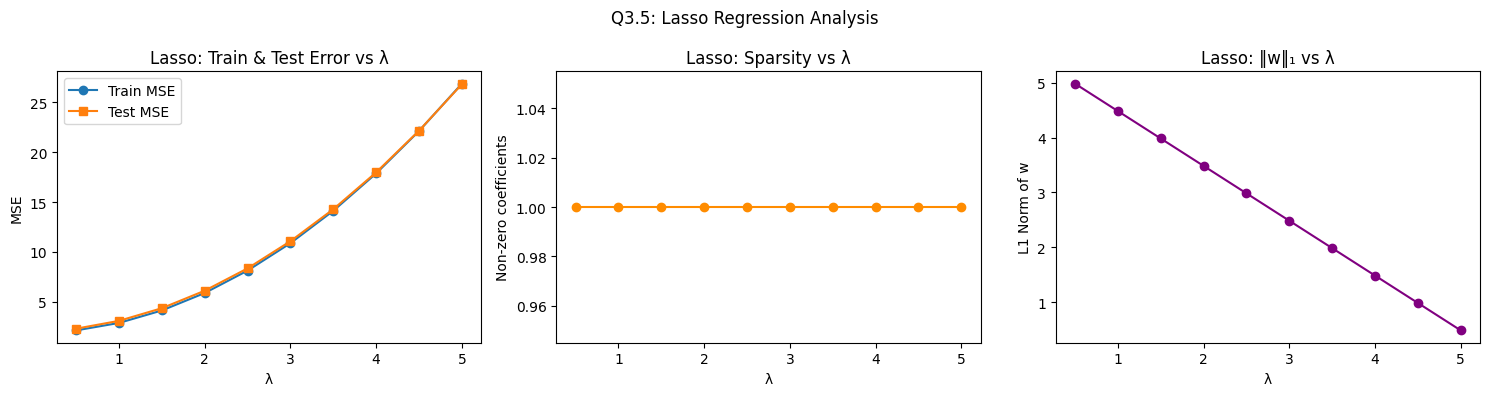

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(lambdas, lasso_train, marker='o', label='Train MSE')
axes[0].plot(lambdas, lasso_test,  marker='s', label='Test MSE')
axes[0].set_xlabel('λ'); axes[0].set_ylabel('MSE')
axes[0].set_title('Lasso: Train & Test Error vs λ')
axes[0].legend()

axes[1].plot(lambdas, lasso_nz, marker='o', color='darkorange')
axes[1].set_xlabel('λ'); axes[1].set_ylabel('Non-zero coefficients')
axes[1].set_title('Lasso: Sparsity vs λ')

axes[2].plot(lambdas, lasso_l1, marker='o', color='purple')
axes[2].set_xlabel('λ'); axes[2].set_ylabel('L1 Norm of w')
axes[2].set_title('Lasso: ‖w‖₁ vs λ')

plt.suptitle('Q3.5: Lasso Regression Analysis', fontsize=12)
plt.tight_layout()
plt.savefig('q3_lasso_analysis.png', dpi=150)
plt.show()

#### Step 5: Ridge Regression (L2)

$$J(w) = \frac{1}{N}\sum_{i=1}^N\left(y_i - (w_0 + w^T\phi(x_i))\right)^2 + \lambda\|w\|_2^2$$

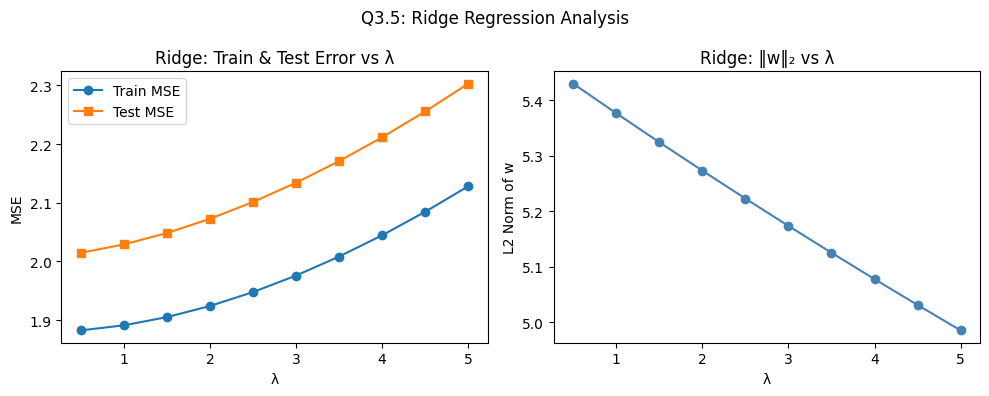

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(lambdas, ridge_train, marker='o', label='Train MSE')
axes[0].plot(lambdas, ridge_test,  marker='s', label='Test MSE')
axes[0].set_xlabel('λ'); axes[0].set_ylabel('MSE')
axes[0].set_title('Ridge: Train & Test Error vs λ')
axes[0].legend()

axes[1].plot(lambdas, ridge_l2, marker='o', color='steelblue')
axes[1].set_xlabel('λ'); axes[1].set_ylabel('L2 Norm of w')
axes[1].set_title('Ridge: ‖w‖₂ vs λ')

plt.suptitle('Q3.5: Ridge Regression Analysis', fontsize=12)
plt.tight_layout()
plt.savefig('q3_ridge_analysis.png', dpi=150)
plt.show()

#### Step 6: Comparison — True Function vs Unregularized vs Lasso vs Ridge

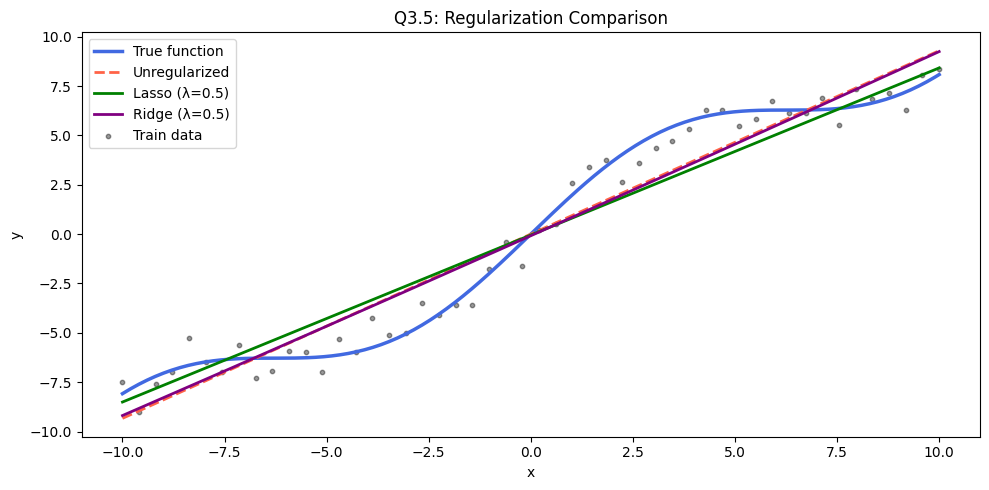

In [21]:
# Best regularized models
lasso_best = make_pipeline(StandardScaler(with_mean=False),
                           Lasso(alpha=lambdas[best_lasso], max_iter=20000, fit_intercept=True))
lasso_best.fit(Xtr, y_train)

ridge_best = make_pipeline(StandardScaler(with_mean=False),
                           Ridge(alpha=lambdas[best_ridge], fit_intercept=True))
ridge_best.fit(Xtr, y_train)

# Unregularized
w_unreg   = np.linalg.pinv(Xtr) @ y_train
unreg_curve = Xte @ w_unreg

plt.figure(figsize=(10, 5))
plt.plot(x_test, y_test,                  color='royalblue', linewidth=2.5, label='True function')
plt.plot(x_test, unreg_curve,             color='tomato',    linewidth=2,   label='Unregularized', linestyle='--')
plt.plot(x_test, lasso_best.predict(Xte), color='green',     linewidth=2,   label=f'Lasso (λ={lambdas[best_lasso]:.1f})')
plt.plot(x_test, ridge_best.predict(Xte), color='purple',    linewidth=2,   label=f'Ridge (λ={lambdas[best_ridge]:.1f})')
plt.scatter(x_train, y_train, s=10, color='black', alpha=0.4, label='Train data')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Q3.5: Regularization Comparison')
plt.legend(); plt.tight_layout()
plt.savefig('q3_regularization_curves_ridge_lasso.png', dpi=150)
plt.show()

**Lasso vs Ridge — Comparison:**

- **Lasso (L1):** Drives many coefficients **exactly to zero** as λ increases — producing a sparse solution. The L1 penalty creates sharp corners in the constraint region, and the optimum tends to land on the axes (zero coefficients). This is effectively automatic feature selection.

- **Ridge (L2):** Shrinks all coefficients toward zero **smoothly**, but never sets them exactly to zero. The L2 constraint region is a smooth sphere with no corners, so coefficients diminish but remain non-zero.

- **Conclusion:** Yes — Lasso produces a **sparser** solution than Ridge. For this problem, where the true function has only a few meaningful components, Lasso's sparsity is more theoretically appropriate. Both methods reduce overfitting compared to the unregularized high-degree fit.

### Q3.6 — Save All Results

In [22]:
results['q3'] = {
    'train_errors':      train_errors,
    'test_errors':       test_errors,
    'bias2':             bias2,
    'variance':          variance,
    'train_err_boot':    train_err_boot,
    'test_err_boot':     test_err_boot,
    'overfit_degree':    overfit_degree,
    'best_lasso_lambda': float(lambdas[best_lasso]),
    'best_ridge_lambda': float(lambdas[best_ridge]),
    'lasso_nz':          lasso_nz,
}

with open('ass1_results.json', 'w', encoding='utf-8') as f:
    json.dump(results, f, indent=2)

print('All results saved to ass1_results.json')

All results saved to ass1_results.json


---
<a id='conclusion'></a>
## Conclusion

### Q1 — Closed-Form Regression
The normal equation gives an exact closed-form solution. On the salary dataset ($w_0=25792.20$, $w_1=9449.96$) and stats_females dataset, results match sklearn to numerical precision. For the singular $X$ case, the pseudoinverse resolves the rank deficiency and returns the minimum-norm least-squares solution.

### Q2 — Gradient Descent
**Batch GD** converges to the closed-form solution exactly (as expected theoretically) and is the most stable. **Mini-batch GD** converges faster per epoch using random subsets. **SGD** is fastest per update but noisiest due to single-sample gradients. All three reach near-identical final weights when learning rates and schedules are properly tuned.

### Q3 — Polynomial Regression, Bias-Variance & Regularization
- Optimal polynomial degree is **7–8** for $f(x) = x + 2\sin(0.5x)$.
- Degrees below 4 underfit; degrees above 9 overfit.
- Bias-variance analysis confirms the classic tradeoff: bias ↓ and variance ↑ with degree.
- **Lasso** produces sparse solutions by zeroing out irrelevant polynomial terms.
- **Ridge** shrinks all coefficients smoothly without sparsity.
- Adding more training data (100 vs 50 points) visibly reduces overfitting at high degrees.



In [23]:
from google.colab import files
import os

# List of all files saved by this notebook
output_files = [
    'ass1_results.json',
    'q2_hypothesis_fit_lines.png',
    'q2_surface_path.png',
    'q2_contour_fit.gif',
    'q3_data.png',
    'q3_poly_fits.png',
    'q3_train_test_generalization_error_vs_degree.png',
    'q3_bias_variance.png',
    'q3_overfit_more_data.png',
    'q3_lasso_analysis.png',
    'q3_ridge_analysis.png',
    'q3_regularization_curves_ridge_lasso.png',
]

print('Downloading files...\n')
for fname in output_files:
    if os.path.exists(fname):
        files.download(fname)
        print(f'✅  {fname}')
    else:
        print(f'❌  {fname}  — NOT FOUND (cell may not have run yet)')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅  ass1_results.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

✅  q3_ridge_analysis.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅  q3_regularization_curves_ridge_lasso.png
